# Dataset: Titanic

[Kaggle dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset/data)

In [4]:
file_id = '1JjQrNza3cQQCx6jZoWZJCIri6ubu13i2'

url = f'https://drive.google.com/uc?id={file_id}'

## Import libraries

In [143]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import RocCurveDisplay

from xgboost import XGBClassifier

## Dataset

In [6]:
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
print('Titanic Dataset')
print('=' * 50)

print(f"Dataset shape: {df.shape}\n")
print(f"{df.info()}\n")

print(df.describe(), '\n')
print(f"Missing value\n{df.isna().sum()}")

print("\nDuplicates:")
print(df.duplicated().sum())

Titanic Dataset
Dataset shape: (891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118  

## EDA

### Bar chart

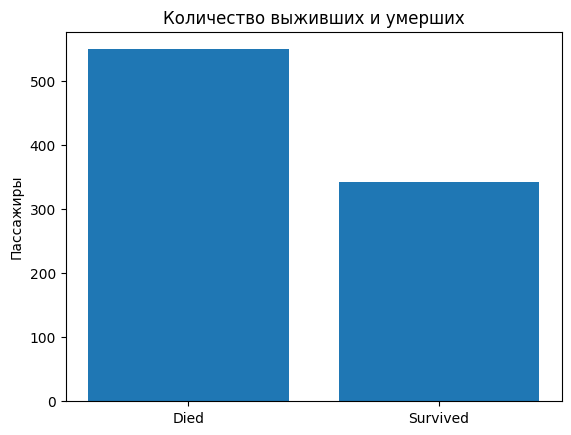


Видно, что выжило куда меньше, чем умерло


In [24]:
results = df['Survived'].value_counts().sort_index()

plt.bar(['Died', 'Survived'], results.values)
plt.title('Количество выживших и умерших')
plt.ylabel('Пассажиры')
plt.show()

print("\nВидно, что выжило куда меньше, чем умерло")


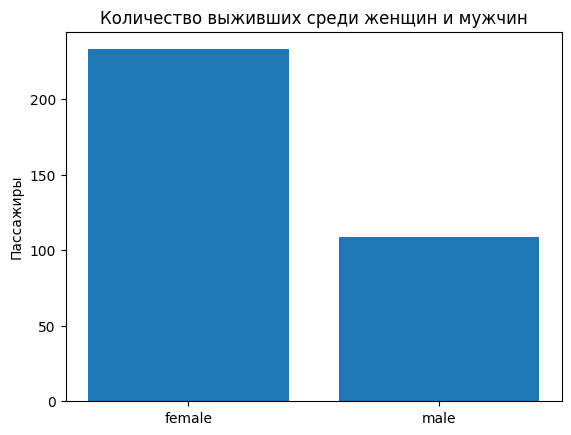


Видно, что женщин выжило намного больше, чем мужчин (это связано с тем, что женщин и детей первыми садили в лодки)


,proportion
Sex,
female,0.681287
male,0.318713


In [79]:
results = (df
 .query('`Survived` == 1')
 .groupby('Sex')
 ['Survived'].sum()
 )

plt.bar(results.index, results.values)
plt.title('Количество выживших среди женщин и мужчин')
plt.ylabel('Пассажиры')
plt.show()

print("\nВидно, что женщин выжило намного больше, чем мужчин (это связано с тем, что женщин и детей первыми садили в лодки)")

df[df['Survived'] == 1]['Sex'].value_counts(normalize=True)

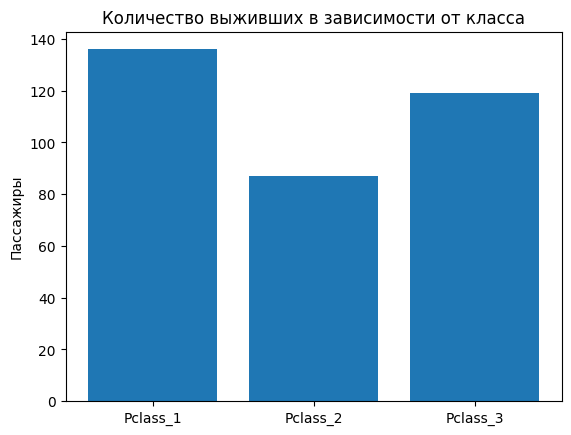


Видно, что преимущественно выжили первые и вторые классы


,proportion
Pclass,
1,0.397661
3,0.347953
2,0.254386


In [78]:
results = (df
 .query('`Survived` == 1')
 .groupby('Pclass')
 ['Survived'].sum()
 )

plt.bar(['Pclass_1', 'Pclass_2', 'Pclass_3'], results.values)
plt.title('Количество выживших в зависимости от класса')
plt.ylabel('Пассажиры')
plt.show()

print("\nВидно, что преимущественно выжили первые и вторые классы")

df[df['Survived'] == 1]['Pclass'].value_counts(normalize=True)


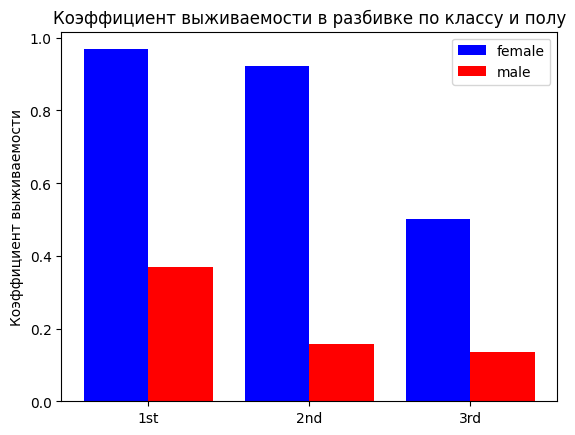

In [31]:
rate = df.pivot_table(values='Survived', index='Pclass', columns='Sex')
x = np.arange(3)

plt.bar(x - 0.2, rate['female'], width=0.4, label='female', color='b')
plt.bar(x + 0.2, rate['male'], width=0.4, label='male', color='r')
plt.xticks(x, ['1st', '2nd', '3rd'])
plt.title('Коэффициент выживаемости в разбивке по классу и полу')
plt.ylabel('Коэффициент выживаемости')
plt.legend()
plt.show()

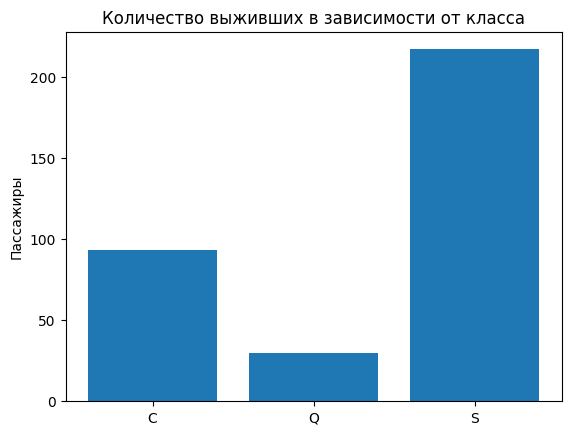


Видно, что преимущественно выжили первые и вторые классы


,proportion
Embarked,
S,0.638235
C,0.273529
Q,0.088235


In [76]:
results = (df
 .query('`Survived` == 1')
 .groupby('Embarked')
 ['Survived'].sum()
 )

plt.bar(results.index, results.values)
plt.title('Количество выживших в зависимости от класса')
plt.ylabel('Пассажиры')
plt.show()

print("\nВидно, что преимущественно выжили первые и вторые классы")

df[df['Survived'] == 1]['Embarked'].value_counts(normalize=True)

## Histogram

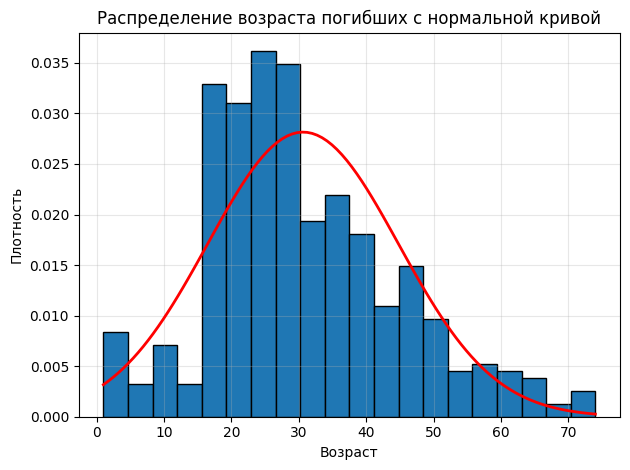

In [59]:
Died = df[df['Survived'] == 0]['Age'].dropna()

plt.hist(Died, bins=20, edgecolor='black', density=True)

mu, sigma = Died.mean(), Died.std()

x = np.linspace(Died.min(), Died.max(), 100)

pdf = norm.pdf(x, mu, sigma)

plt.plot(x, pdf, 'r-', linewidth=2)

plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.title('Распределение возраста погибших с нормальной кривой')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

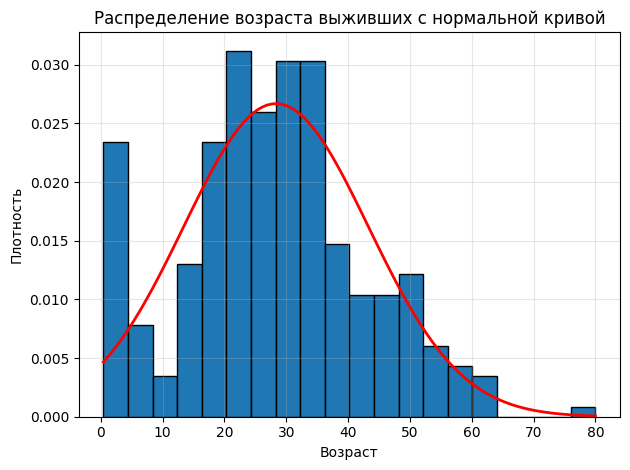

In [60]:
Survived = df[df['Survived'] == 1]['Age'].dropna()

plt.hist(Survived, bins=20, edgecolor='black', density=True)

mu, sigma = Survived.mean(), Survived.std()

x = np.linspace(Survived.min(), Survived.max(), 100)

pdf = norm.pdf(x, mu, sigma)

plt.plot(x, pdf, 'r-', linewidth=2)

plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.title('Распределение возраста выживших с нормальной кривой')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Heatmap


Очень слабые корреляции между колонками, топ связанных пар можно считать SibSp - Parch, Survived - Fare



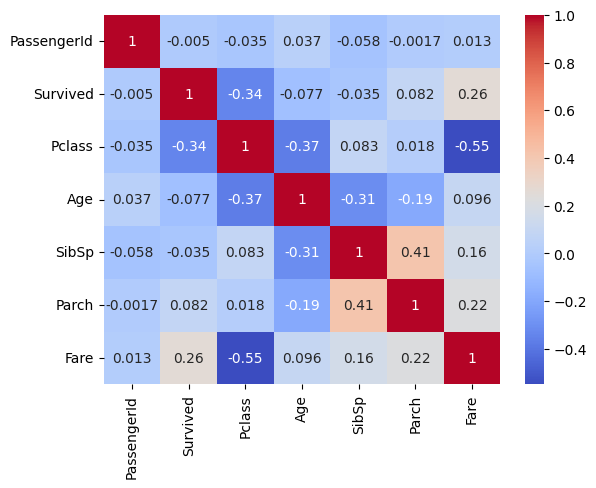

In [86]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

print("\nОчень слабые корреляции между колонками, топ связанных пар можно считать SibSp - Parch, Survived - Fare\n")


## Filling gaps

In [179]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['CabinKnown'] = df['Cabin'].notna().astype(int)
df['Age'] = df.groupby(['Sex', 'Pclass'])['Age'].transform('median')

In [180]:
df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Change dtype

In [119]:
df['Embarked'] = pd.Categorical(df['Embarked'])

## Encoding

In [127]:
df_encoded = pd.get_dummies(df, columns=['Sex', 'Embarked'])
df_encoded['Sex_female'] = df_encoded['Sex_female'].astype('int64')
df_encoded['Sex_male'] = df_encoded['Sex_male'].astype('int64')

df_encoded['Embarked_C'] = df_encoded['Embarked_C'].astype('int64')
df_encoded['Embarked_Q'] = df_encoded['Embarked_Q'].astype('int64')
df_encoded['Embarked_S'] = df_encoded['Embarked_S'].astype('int64')
df_encoded.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,CabinKnown,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,0,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,1,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,1,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,0,0,1,0,0,1


## Train, test split

In [152]:
X = df_encoded.drop(columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
y = df_encoded['Survived']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [132]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Logistic Regression

In [133]:
model_logreg = LogisticRegression()
model_logreg.fit(x_train_scaled, y_train)

LogisticRegression()

Accuracy: 0.8212
Precision: 0.8000
Recall: 0.7568
F1-score: 0.7778
ROC-AUC: 0.8802


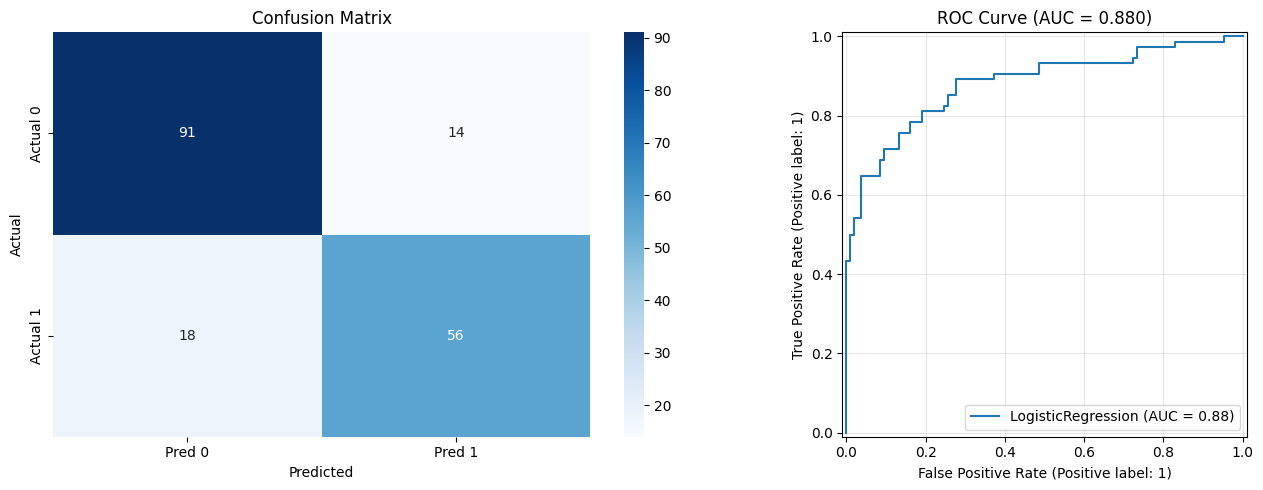

In [151]:
y_pred = model_logreg.predict(x_test_scaled)
y_proba = model_logreg.predict_proba(x_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')
roc_auc = roc_auc_score(y_test, y_proba)

# Вывод метрик
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. confusion matrix
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred 0', 'Pred 1'],
    yticklabels=['Actual 0', 'Actual 1'],
    ax=axes[0]
    )
axes[0].set_title(f'Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# 2. ROC-кривая
RocCurveDisplay.from_estimator(model_logreg, x_test_scaled, y_test, ax=axes[1])
axes[1].set_title(f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Random Forest

In [156]:
model_forest = RandomForestClassifier(random_state=2, max_depth=30)
model_forest.fit(x_train_scaled, y_train)

RandomForestClassifier(max_depth=30, random_state=2)

Accuracy: 0.4972
Precision: 0.4068
Recall: 0.3038
F1-score: 0.3478
ROC-AUC: 0.4858


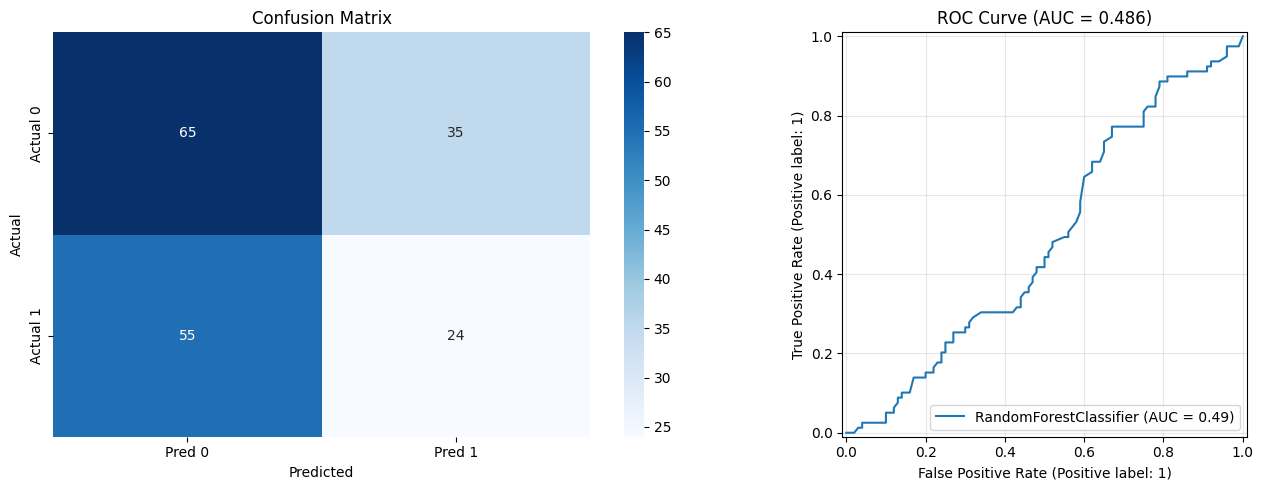

In [159]:
y_pred = model_forest.predict(x_test_scaled)
y_proba = model_forest.predict_proba(x_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')
roc_auc = roc_auc_score(y_test, y_proba)

# Вывод метрик
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. confusion matrix
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred 0', 'Pred 1'],
    yticklabels=['Actual 0', 'Actual 1'],
    ax=axes[0]
    )
axes[0].set_title(f'Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# 2. ROC-кривая
RocCurveDisplay.from_estimator(model_forest, x_test_scaled, y_test, ax=axes[1])
axes[1].set_title(f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## XGBoost

In [174]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(
    random_state=2,
    max_depth=12,
    n_estimators=100,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss'
)

model_xgb.fit(x_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:09:06] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=12, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

Accuracy: 0.5307
Precision: 0.4545
Recall: 0.3165
F1-score: 0.3731
ROC-AUC: 0.4808


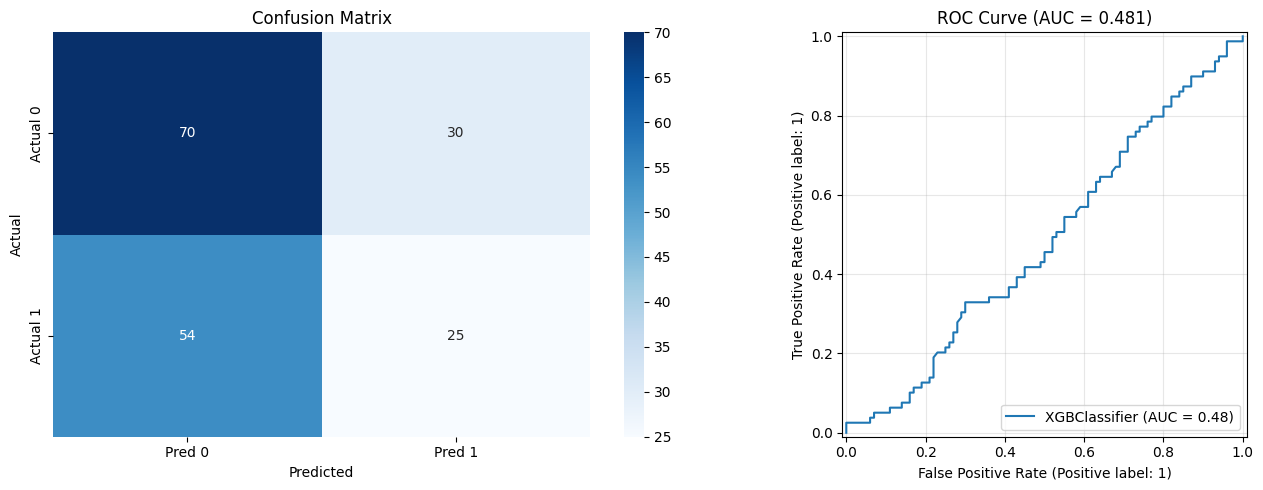

In [173]:

y_pred_xgb = model_xgb.predict(x_test_scaled)
y_proba_xgb = model_xgb.predict_proba(x_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred_xgb)
prec = precision_score(y_test, y_pred_xgb, average='binary')
rec = recall_score(y_test, y_pred_xgb, average='binary')
f1 = f1_score(y_test, y_pred_xgb, average='binary')
roc_auc = roc_auc_score(y_test, y_proba_xgb)

# Вывод метрик
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_pred_xgb)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. confusion matrix
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred 0', 'Pred 1'],
    yticklabels=['Actual 0', 'Actual 1'],
    ax=axes[0]
    )
axes[0].set_title(f'Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# 2. ROC-кривая
RocCurveDisplay.from_estimator(model_xgb, x_test_scaled, y_test, ax=axes[1])
axes[1].set_title(f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Model comparison table

In [176]:
import time

# Словарь для хранения результатов
results = {}

# Логистическая регрессия
start_time = time.time()
model_logreg = LogisticRegression(random_state=2)
model_logreg.fit(x_train_scaled, y_train)
logreg_train_time = time.time() - start_time

start_time = time.time()
y_pred_logreg = model_logreg.predict(x_test_scaled)
y_proba_logreg = model_logreg.predict_proba(x_test_scaled)[:, 1]
logreg_pred_time = time.time() - start_time

results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_logreg),
    'Precision': precision_score(y_test, y_pred_logreg),
    'Recall': recall_score(y_test, y_pred_logreg),
    'F1-score': f1_score(y_test, y_pred_logreg),
    'ROC-AUC': roc_auc_score(y_test, y_proba_logreg),
    'Train Time (s)': logreg_train_time,
    'Predict Time (s)': logreg_pred_time
}

# Random Forest
start_time = time.time()
model_forest = RandomForestClassifier(random_state=2, max_depth=30)
model_forest.fit(x_train_scaled, y_train)
forest_train_time = time.time() - start_time

start_time = time.time()
y_pred_forest = model_forest.predict(x_test_scaled)
y_proba_forest = model_forest.predict_proba(x_test_scaled)[:, 1]
forest_pred_time = time.time() - start_time

results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_forest),
    'Precision': precision_score(y_test, y_pred_forest),
    'Recall': recall_score(y_test, y_pred_forest),
    'F1-score': f1_score(y_test, y_pred_forest),
    'ROC-AUC': roc_auc_score(y_test, y_proba_forest),
    'Train Time (s)': forest_train_time,
    'Predict Time (s)': forest_pred_time
}

# XGBoost
start_time = time.time()
model_xgb = XGBClassifier(
    random_state=2,
    max_depth=12,
    n_estimators=100,
    learning_rate=0.1,
    eval_metric='logloss'
)
model_xgb.fit(x_train_scaled, y_train)
xgb_train_time = time.time() - start_time

start_time = time.time()
y_pred_xgb = model_xgb.predict(x_test_scaled)
y_proba_xgb = model_xgb.predict_proba(x_test_scaled)[:, 1]
xgb_pred_time = time.time() - start_time

results['XGBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'Recall': recall_score(y_test, y_pred_xgb),
    'F1-score': f1_score(y_test, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_proba_xgb),
    'Train Time (s)': xgb_train_time,
    'Predict Time (s)': xgb_pred_time
}

# Создание и вывод таблицы
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df.round(4)
print("Сравнение моделей:")
display(comparison_df)

Сравнение моделей:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train Time (s),Predict Time (s)
Logistic Regression,0.5642,1.0000,0.0127,0.0250,0.5409,0.0190,0.0008
Random Forest,0.4972,0.4068,0.3038,0.3478,0.4858,0.2476,0.0309
XGBoost,0.5307,0.4545,0.3165,0.3731,0.4808,1.0260,0.0050


Лучшая модель — логистическая регрессия. Я выбрал её по трём причинам:

Качество: у неё лучший ROC-AUC 0.88 и F1-score среди всех моделей.

Скорость: обучается и предсказывает быстрее Random Forest, XGBoost.

Простота и интерпретируемость: Логистическая регрессия проста для понимания. Мы можем посмотреть на коэффициенты модели и понять, какие признаки и как влияют на вероятность выживания.

Random Forest и XGBoost показали слабые результаты.

## Save model

In [177]:
import pickle

# Сохраняем лучшую модель Logistic Regression
with open('best_model_logreg.pkl', 'wb') as f:
    pickle.dump(model_logreg, f)

# Также сохраним scaler, так как он использовался для обучения
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Модель и scaler сохранены в файлы 'best_model_logreg.pkl' и 'scaler.pkl'")

Модель и scaler сохранены в файлы 'best_model_logreg.pkl' и 'scaler.pkl'
